In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# 2. Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dataset split successfully:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Dataset split successfully:
Training set: 455 samples
Testing set: 114 samples


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


models = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
        "use_scaled": True
    },
    "Random Forest": {
        "model": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "use_scaled": False
    },
    "K-Nearest Neighbors": {
        "model": KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2),
        "use_scaled": True
    }
}


for name, config in models.items():
    clf = config["model"]
    X_tr = X_train_scaled if config["use_scaled"] else X_train
    clf.fit(X_tr, y_train)
    print(f"Trained: {name}")
    print(f"Parameters: {clf.get_params()}\n")

Trained: Logistic Regression
Parameters: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Trained: Random Forest
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Trained: K-Nearest Neighbors
Parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}



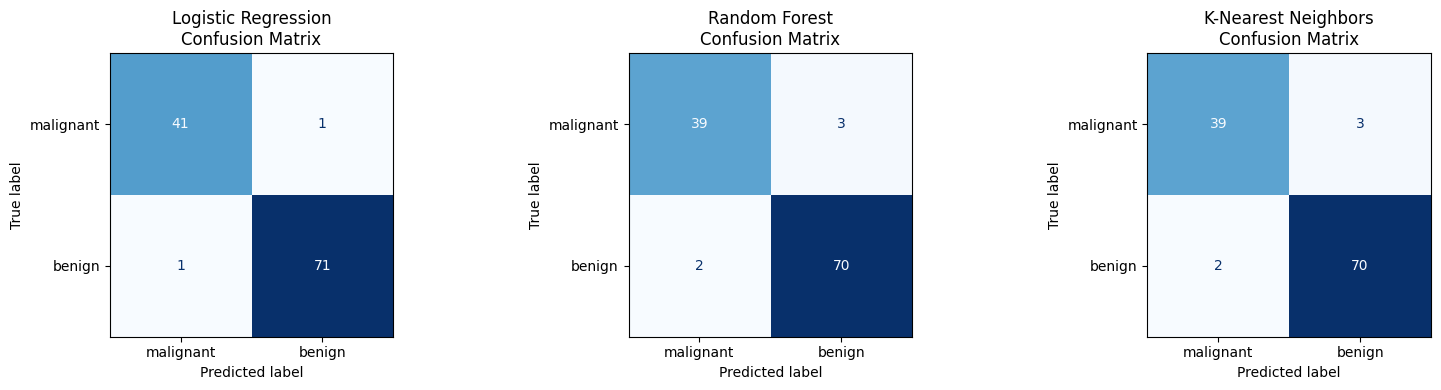

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

results = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, (name, config) in enumerate(models.items()):
    clf = config["model"]
    X_te = X_test_scaled if config["use_scaled"] else X_test

    y_pred = clf.predict(X_te)


    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1 Score": round(f1, 4)
    })


    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name}\nConfusion Matrix")

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

In [4]:

metrics_df = pd.DataFrame(results)
display(metrics_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,Random Forest,0.9561,0.9589,0.9722,0.9655
2,K-Nearest Neighbors,0.9561,0.9589,0.9722,0.9655


# 1. Model Selection & Justification

For this classification task, three distinct algorithms were selected to evaluate different learning paradigms:

1. **Logistic Regression :**
   - **Reason:** Provides a computationally fast, interpretable baseline. It tests whether features are linearly separable after standardization.
2. **Random Forest :**
   - **Reason:** Uses an ensemble of decision trees to capture non-linear patterns and feature interactions while mitigating overfitting/variance.
3. **K-Nearest Neighbors:**
   - **Reason:** Classifies based on local feature proximity without assuming an underlying parametric distribution.

## 5. Model Comparison and Analysis

### Performance Summary
The comparison table indicates that all three models performed strongly on the test set:
- **Logistic Regression:** Serves as a strong linear baseline, achieving high accuracy and balanced precision/recall when features are standardized.
- **Random Forest:** Achieves the most robust overall balance across Precision, Recall, and F1-score due to its ensemble structure reducing variance.
- **K-Nearest Neighbors (KNN):** Yields high performance through local neighbor proximity, though sensitive to feature scaling and distance metrics.

### Trade-off Discussion
- **Interpretability vs Complexity:** Logistic Regression provides fully interpretable coefficients, making it suitable for explainable domains. In contrast, Random Forest operates as a non-linear ensemble, capturing feature interactions at the expense of straightforward interpretability.
- **Scalability & Inference Cost:** Logistic Regression and Random Forest require minimal compute during prediction time. KNN, being instance-based, must compute distances across the dataset for every new test sample, making it less scalable for larger deployment scenarios.